In [379]:
from sklearn.datasets import load_iris


from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn import tree
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

In [380]:
df=pd.read_csv("dataset.csv")
df

,Student_ID,Study_Hours,Attendance_Percent,Previous_Score,Assignments_Completed,Sleep_Hours,Internet_Access,Extra_Classes,Result
0,1,2,41,60,3,5,Yes,Yes,Fail
1,2,9,45,79,0,4,Yes,Yes,Pass
2,3,9,78,28,8,5,No,Yes,Pass
3,4,10,57,25,2,9,No,No,Fail
4,5,3,53,68,1,4,No,Yes,Fail
...,...,...,...,...,...,...,...,...,...
195,196,1,60,46,9,7,No,Yes,Fail
196,197,2,55,80,9,7,Yes,No,Pass
197,198,6,54,67,2,4,Yes,Yes,Pass
198,199,6,62,43,3,4,Yes,No,Fail


In [381]:
df.isnull().sum()

Student_ID               0
Study_Hours              0
Attendance_Percent       0
Previous_Score           0
Assignments_Completed    0
Sleep_Hours              0
Internet_Access          0
Extra_Classes            0
Result                   0
dtype: int64

In [382]:
x=df.drop(columns=["Internet_Access", "Extra_Classes","Result"])
x

,Student_ID,Study_Hours,Attendance_Percent,Previous_Score,Assignments_Completed,Sleep_Hours
0,1,2,41,60,3,5
1,2,9,45,79,0,4
2,3,9,78,28,8,5
3,4,10,57,25,2,9
4,5,3,53,68,1,4
...,...,...,...,...,...,...
195,196,1,60,46,9,7
196,197,2,55,80,9,7
197,198,6,54,67,2,4
198,199,6,62,43,3,4


In [383]:
y=df["Result"]
y

0      Fail
1      Pass
2      Pass
3      Fail
4      Fail
       ... 
195    Fail
196    Pass
197    Pass
198    Fail
199    Pass
Name: Result, Length: 200, dtype: str

In [384]:
df.head(3)

,Student_ID,Study_Hours,Attendance_Percent,Previous_Score,Assignments_Completed,Sleep_Hours,Internet_Access,Extra_Classes,Result
0,1,2,41,60,3,5,Yes,Yes,Fail
1,2,9,45,79,0,4,Yes,Yes,Pass
2,3,9,78,28,8,5,No,Yes,Pass


In [385]:
print(df.columns.tolist())

['Student_ID', 'Study_Hours', 'Attendance_Percent', 'Previous_Score', 'Assignments_Completed', 'Sleep_Hours', 'Internet_Access', 'Extra_Classes', 'Result']


In [386]:
df.shape

(200, 9)

In [387]:
df.describe()

,Student_ID,Study_Hours,Attendance_Percent,Previous_Score,Assignments_Completed,Sleep_Hours
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,5.545000,70.390000,61.860000,5.045000,6.755000
std,57.879185,2.842247,16.934633,20.105511,3.341978,1.791935
min,1.000000,1.000000,40.000000,25.000000,0.000000,4.000000
25%,50.750000,3.000000,55.000000,44.000000,2.000000,5.000000
50%,100.500000,6.000000,72.000000,63.000000,5.000000,7.000000
75%,150.250000,8.000000,84.000000,79.000000,8.000000,8.000000
max,200.000000,10.000000,100.000000,95.000000,10.000000,9.000000


In [388]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Student_ID             200 non-null    int64
 1   Study_Hours            200 non-null    int64
 2   Attendance_Percent     200 non-null    int64
 3   Previous_Score         200 non-null    int64
 4   Assignments_Completed  200 non-null    int64
 5   Sleep_Hours            200 non-null    int64
 6   Internet_Access        200 non-null    str  
 7   Extra_Classes          200 non-null    str  
 8   Result                 200 non-null    str  
dtypes: int64(6), str(3)
memory usage: 14.2 KB


In [389]:
x.head(3)

,Student_ID,Study_Hours,Attendance_Percent,Previous_Score,Assignments_Completed,Sleep_Hours
0,1,2,41,60,3,5
1,2,9,45,79,0,4
2,3,9,78,28,8,5


In [390]:
y.head(3)

0    Fail
1    Pass
2    Pass
Name: Result, dtype: str

In [391]:
x_train, x_test, y_train, y_test =train_test_split(
    x, y,
     random_state=42,
     test_size=0.2
)

In [392]:
model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42,
    max_depth=2
)


In [393]:
model.fit(x_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [394]:
y_pred=model.predict(x_test)

In [395]:
accuracy=accuracy_score(y_pred,y_test)
print("Accuracy",accuracy)

Accuracy 0.75


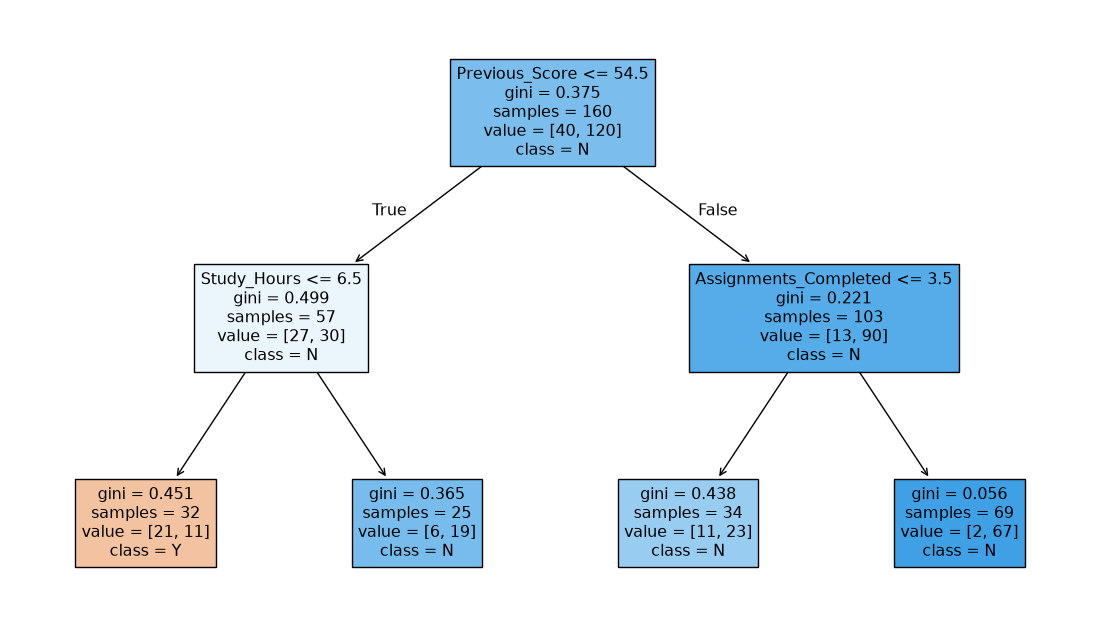

In [396]:
plt.figure(figsize=(14, 8))
tree.plot_tree(
    model,
    feature_names=x.columns,    
    class_names=['Y','N'],         
    filled=True
)
plt.show()